In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 4.7 — The trace as a closed diagram and its cyclicity

**Source.** SMSA 7.8, 2026-11-05 (local `smsa.pdf`, SHA-256 `6922b174…813b8fe`). References are section and equation numbers of that version.

**Translation conventions.** `f >> g` is SMSA's $g\circ f$ (first $f$, then $g$); `f @ g` is $f\otimes g$ with the left factor on the left. Native DisCoPy drawings read **top to bottom**, SMSA reads bottom to top; left-to-right order is unchanged. Only built-in DisCoPy 1.2.2 objects and methods are used: no custom functions, classes or rewrite rules. Checks print the computed and expected values with a comparison result and continue when a comparison is `False`.

SMSA (4.72) defines the right trace of $f\colon V\to V$ by closing the $f$ wire with a coevaluation $1\to V\otimes V^*$ below and an evaluation $V\otimes V^*\to 1$ above. In DisCoPy's `compact` module the bend with codomain `V @ V.r` is `Cap(V, V.r)` and the bend with domain `V @ V.r` is `Cup(V, V.r)`. So **here** $V^*$ is `V.r`, whereas the snake notebook for §2.5 matched $V^*$ to `V.l` from the ordered domain $V^*\otimes V$ of (2.85). The type order decides the name, and in a compact (pivotal) category both names denote the same type.

In [1]:
from discopy import compact, tensor
from discopy.drawing import Equation
import numpy as np

V, W = compact.Ty('V'), compact.Ty('W')
f = compact.Box('f', V, W)
g = compact.Box('g', W, V)
print('V.l == V.r in the compact module:', V.l == V.r)
print('Cap(V, V.r):', compact.Cap(V, V.r).dom, '->', compact.Cap(V, V.r).cod)
print('Cup(V, V.r):', compact.Cup(V, V.r).dom, '->', compact.Cup(V, V.r).cod)

V.l == V.r in the compact module: True
Cap(V, V.r): Ty() -> V @ V.r
Cup(V, V.r): V @ V.r -> Ty()


The built-in `trace()` closes the rightmost wire. Compare it with the diagram written out by hand from (4.72): coevaluation, then $g\circ f$ on the left wire, then evaluation.

trace(): Cap(V, V.r) >> f @ V.r >> g @ V.r >> Cup(V, V.r)
boundary: Ty() -> Ty()   (empty type = tensor unit)
same diagram as the hand-written (4.72)? True


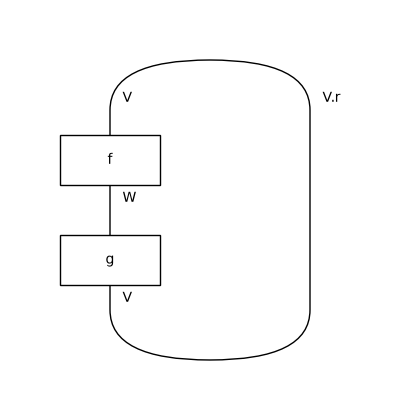

In [2]:
tr_gf = (f >> g).trace()
by_hand = compact.Cap(V, V.r) >> (f @ compact.Id(V.r)) >> (g @ compact.Id(V.r)) >> compact.Cup(V, V.r)
print('trace():', tr_gf)
print('boundary:', tr_gf.dom, '->', tr_gf.cod, '  (empty type = tensor unit)')
print('same diagram as the hand-written (4.72)?', tr_gf == by_hand)
tr_gf.draw(figsize=(4, 4))

**Lemma 4.7.14, (4.80):** $\mathrm{tr}_V(g\circ f)=\mathrm{tr}_W(f\circ g)$. The two closed diagrams are different free diagrams, and the rigid normal form of this release does not identify them: sliding a box around the loop is not among its rewrites. So the next cell shows a typing agreement and a `False` for free equality; the equality is then checked in a model.

both are closed diagrams: True
equal as free diagrams: False
equal after normal_form(): False


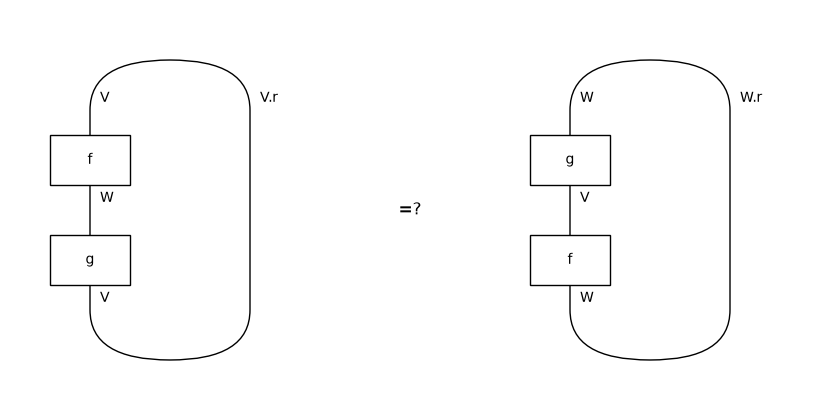

In [3]:
tr_fg = (g >> f).trace()
Equation(tr_gf, tr_fg, symbol='=?').draw(figsize=(8, 4))
print('both are closed diagrams:', tr_gf.dom == tr_fg.dom == compact.Ty() and tr_gf.cod == tr_fg.cod == compact.Ty())
print('equal as free diagrams:', tr_gf == tr_fg)
print('equal after normal_form():', tr_gf.normal_form() == tr_fg.normal_form())

**Model check.** Take $\dim V=3$, $\dim W=2$. The rectangular maps make input/output shapes explicit. Cyclicity deliberately gives equal traces even though the two composite matrices have different sizes; scalar trace equality alone cannot detect every transpose mistake. DisCoPy input axes precede output axes, so supply conventional column matrices as `M.T`. We check the full composite matrices before closing their wires.

In [4]:
M_f = np.array([[1, 2, 0],
                [3, 4, 5]])      # f: V -> W, a 2 x 3 matrix
M_g = np.array([[1, 0],
                [2, 1],
                [0, 3]])         # g: W -> V, a 3 x 2 matrix
F = tensor.Functor({V: 3, W: 2}, {f: M_f.T, g: M_g.T}, dom=compact.Category(), dtype=int)
print('F(tr_V(g o f)) =', F(tr_gf).array, '  numpy trace(M_g @ M_f) =', np.trace(M_g @ M_f))
print('F(tr_W(f o g)) =', F(tr_fg).array, '  numpy trace(M_f @ M_g) =', np.trace(M_f @ M_g))
print('(4.80) holds in this model:', F(tr_gf) == F(tr_fg))
for label, diagram, expected in [('g after f', f >> g, M_g @ M_f), ('f after g', g >> f, M_f @ M_g)]:
    actual = F(diagram).array.T
    print(label, 'actual matrix:', actual, 'expected:', expected, 'match:', np.array_equal(actual, expected))

F(tr_V(g o f)) = 24   numpy trace(M_g @ M_f) = 24
F(tr_W(f o g)) = 24   numpy trace(M_f @ M_g) = 24
(4.80) holds in this model: True
g after f actual matrix: [[ 1  2  0]
 [ 5  8  5]
 [ 9 12 15]] expected: [[ 1  2  0]
 [ 5  8  5]
 [ 9 12 15]] match: True
f after g actual matrix: [[ 5  2]
 [11 19]] expected: [[ 5  2]
 [11 19]] match: True


**The actual spiral in (4.81).** With the declared top-to-bottom conversion, the current SMSA picture matches two native *left* transposes: input $V$ stays on the left, output $W$ on the right, and the nested loops have the source order. Native bend arrows are omitted. This compact-diagram expression evaluates to $f$; `normal_form()` in 1.2.2 does not remove this spiral. For comparison, a right transpose followed by a left transpose does reduce by the snake rules, but draws a different, zigzag arrangement. Distinguish that useful native rewrite from a literal transcription of (4.81).

(4.81) spiral boundary: V -> W
Spiral normal form: V @ Cap(W.r, W) >> V @ W.r @ Cap(V, V.r) @ W >> V @ W.r @ f @ V.r @ W >> V @ Cup(W.r, W) @ V.r @ W >> Cup(V, V.r) @ W
Expected f: f ; native normal form equals f: False
Spiral model matrix: [[1 2 0]
 [3 4 5]]
Expected matrix: [[1 2 0]
 [3 4 5]] ; equal: True
Comparison zigzag normal form: f ; equals f: True
Single transpose column matrix: [[1 3]
 [2 4]
 [0 5]]
Expected transpose: [[1 3]
 [2 4]
 [0 5]] ; match: True


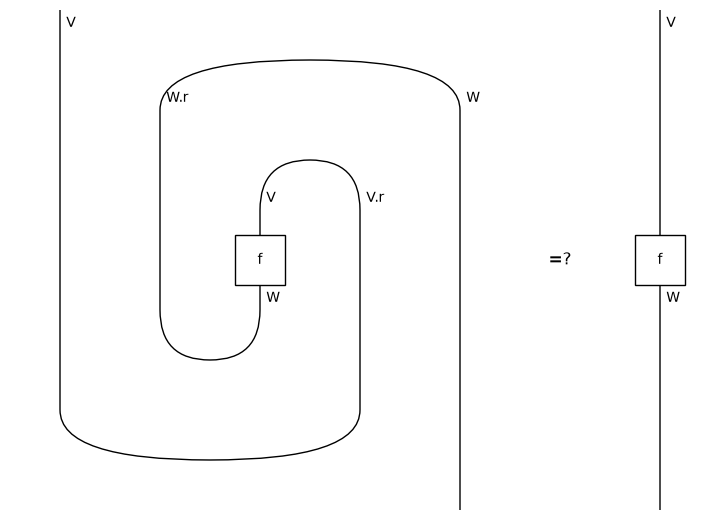

In [5]:
f_t = f.transpose()
f_spiral = f.transpose(left=True).transpose(left=True)
f_zigzag = f_t.transpose(left=True)
print('(4.81) spiral boundary:', f_spiral.dom, '->', f_spiral.cod)
print('Spiral normal form:', f_spiral.normal_form())
print('Expected f:', f, '; native normal form equals f:', f_spiral.normal_form() == f)
Equation(f_spiral, f, symbol='=?').draw(figsize=(7, 5))
print('Spiral model matrix:', F(f_spiral).array.T)
print('Expected matrix:', M_f, '; equal:', F(f_spiral) == F(f))
print('Comparison zigzag normal form:', f_zigzag.normal_form(), '; equals f:', f_zigzag.normal_form() == f)
print('Single transpose column matrix:', F(f_t).array.T)
print('Expected transpose:', M_f.T, '; match:', np.array_equal(F(f_t).array.T, M_f.T))

**Characters, (4.73) and (4.79).** For a representation $D$ the character is the closed diagram $\chi_D(g)=\mathrm{tr}_V D(g)$. Take the permutation representation of $S_3$ on $\mathbb C^3$: $D(g)$ permutes the basis vectors. Each $D(g)$ is a box with its permutation matrix, and `trace()` closes it. The character counts fixed points, $\chi_D(e)=\dim V$ is (4.79), and cyclicity (4.80) makes $\chi_D$ constant on conjugacy classes: the trace of $D(h)\,D(g)\,D(h)^{-1}$ is drawn as the box of $g$ with the boxes of $h$ and $h^{-1}$ around it on the loop.

chi( e ) = 3   fixed points: 3   match: True
chi( (12) ) = 1   fixed points: 1   match: True
chi( (123) ) = 0   fixed points: 0   match: True
(4.79) chi(e) == dim V: True
chi((12)(123)(12)) = 0   chi((123)) = 0   class function: True
repr of the scalar boundary: pivotal.Ty() -> pivotal.Ty()


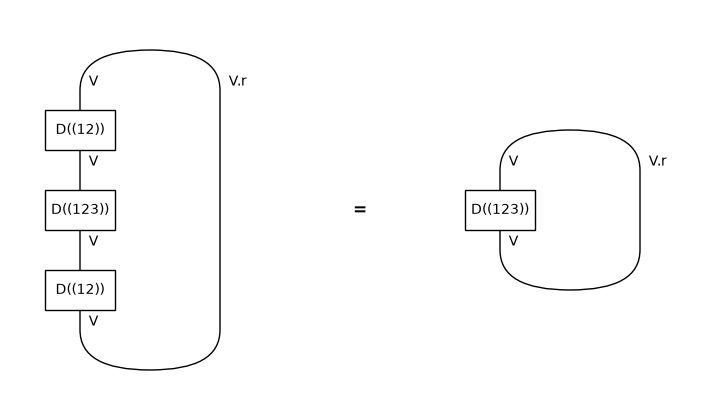

In [6]:
D_e = compact.Box('D(e)', V, V)
D_12 = compact.Box('D((12))', V, V)
D_123 = compact.Box('D((123))', V, V)
P_e = np.eye(3, dtype=int)
P_12 = np.array([[0, 1, 0], [1, 0, 0], [0, 0, 1]])      # swaps basis vectors 1 and 2
P_123 = np.array([[0, 0, 1], [1, 0, 0], [0, 1, 0]])     # sends e1 -> e2 -> e3 -> e1
R = tensor.Functor({V: 3}, {D_e: P_e.T, D_12: P_12.T, D_123: P_123.T}, dom=compact.Category(), dtype=int)
for name, box, fixed in [('e', D_e, 3), ('(12)', D_12, 1), ('(123)', D_123, 0)]:
    print('chi(', name, ') =', R(box.trace()).array, '  fixed points:', fixed, '  match:', int(R(box.trace()).array) == fixed)
print('(4.79) chi(e) == dim V:', int(R(D_e.trace()).array) == 3)
conjugated = (D_12 >> D_123 >> D_12).trace()     # (12)(123)(12) = (132), the inverse of (123); D((12)) is its own inverse
Equation(conjugated, D_123.trace(), symbol='=').draw(figsize=(7, 4))
print('chi((12)(123)(12)) =', R(conjugated).array, '  chi((123)) =', R(D_123.trace()).array, '  class function:', R(conjugated) == R(D_123.trace()))
print('repr of the scalar boundary:', repr(conjugated.dom), '->', repr(conjugated.cod))

### The element coupon, the character through the action box, and the left trace: (4.74)–(4.78)

SMSA (4.74) draws a group element $g$ as a coupon with no input and one output on the group wire, in the same way as a vector in (2.28). With the two-input action box $D$ of (4.23) the character becomes the picture (4.75): the element coupon feeds the group input of $D$, and the $V$ wire is closed by a loop. Leaving the element off gives (4.76), a diagram with one open group wire, which is the character as a function on $G$; (4.77) writes it as evaluation after $D\otimes\mathrm{id}_{V^*}$ after $\mathrm{id}_G\otimes\mathrm{coev}$. The group wire must be a vector space, so, as in `smsa_04_02.ipynb`, the group is replaced by its group algebra, which Remark 4.7.11 says makes everything literally correct. The example is the regular representation of $\mathbb Z_2$ on $V=\mathbb F[\mathbb Z_2]$ from `smsa_04_02.ipynb`: $D(b_0)$ is the identity and $D(b_1)$ exchanges the two basis vectors, so $\chi(e)=2$ and $\chi(g)=0$. Here `V` is given dimension $2$ by a new functor; the trace cells above use the same type with dimension $3$.

(4.74) element coupon g: boundary Ty() -> G ; coefficients on b_0, b_1: [0 1]
(4.75) chi(e) = 2 ; chi(g) = 0 ; expected traces of D(e) = I and D(g) = swap: 2, 0
Match: True


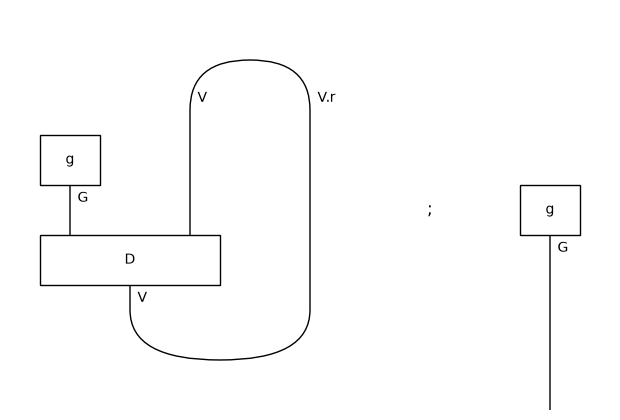

In [7]:
G = compact.Ty('G')
act = compact.Box('D', G @ V, V)
elem_e = compact.Box('e', compact.Ty(), G)
elem_g = compact.Box('g', compact.Ty(), G)
regular = [[[int(k == (i + j) % 2) for k in range(2)] for j in range(2)] for i in range(2)]
Z = tensor.Functor({G: 2, V: 2}, {act: regular, elem_e: [1, 0], elem_g: [0, 1]}, dom=compact.Category(), dtype=int)
chi_e = ((elem_e @ compact.Id(V)) >> act).trace()
chi_g = ((elem_g @ compact.Id(V)) >> act).trace()
Equation(chi_g, elem_g, symbol=';').draw(figsize=(6, 4))
print('(4.74) element coupon g: boundary', elem_g.dom, '->', elem_g.cod, '; coefficients on b_0, b_1:', Z(elem_g).array)
print('(4.75) chi(e) =', Z(chi_e).array, '; chi(g) =', Z(chi_g).array, '; expected traces of D(e) = I and D(g) = swap: 2, 0')
print('Match:', int(Z(chi_e).array) == 2 and int(Z(chi_g).array) == 0)


(4.76) boundary: G -> Ty() ; a function on the group wire
(4.77) composite equals the native trace of the action box as a free diagram: True
chi as a vector on b_0, b_1: [2 0] ; expected (2, 0)
Feeding the element coupons into (4.76) gives (4.75): True


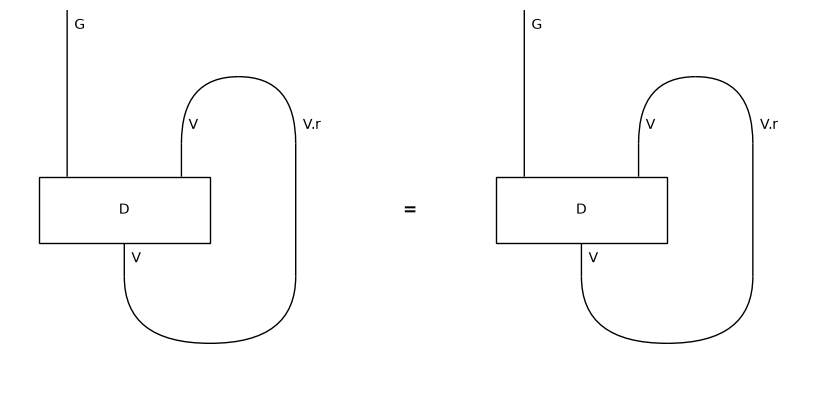

In [8]:
chi = act.trace()
chi_477 = (compact.Id(G) @ compact.Cap(V, V.r)) >> (act @ compact.Id(V.r)) >> compact.Cup(V, V.r)
Equation(chi, chi_477, symbol='=').draw(figsize=(8, 4))
print('(4.76) boundary:', chi.dom, '->', chi.cod, '; a function on the group wire')
print('(4.77) composite equals the native trace of the action box as a free diagram:', chi == chi_477)
print('chi as a vector on b_0, b_1:', Z(chi).array, '; expected (2, 0)')
print('Feeding the element coupons into (4.76) gives (4.75):', Z(elem_e >> chi) == Z(chi_e) and Z(elem_g >> chi) == Z(chi_g))


**The left trace (4.78).** The right trace (4.72) bends the output of $f$ to the right; the left trace bends it to the left, with $V^*$ on the left of the box, using the other pair of bends. The library has it as `trace(left=True)`. The two closed diagrams are different pictures and the free comparison prints `False`; in the matrix model both are the ordinary trace, as 4.7.12 says, checked here for $g\circ f$ of the cells above and for the $S_3$ permutation matrices.

trace(left=True) equals the hand-written (4.78): True
Left and right loops equal as free diagrams: False
Left trace of g o f: 24 ; right trace: 24 ; equal in the model: True
S3 character of e by the left trace: 3 ; by the right trace: 3 ; equal: True
S3 character of (12) by the left trace: 1 ; by the right trace: 1 ; equal: True
S3 character of (123) by the left trace: 0 ; by the right trace: 0 ; equal: True


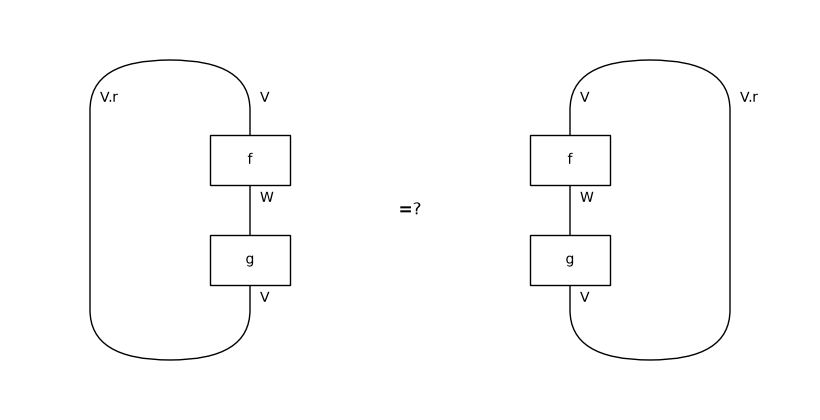

In [9]:
left_gf = (f >> g).trace(left=True)
left_by_hand = compact.Cap(V.r, V) >> (compact.Id(V.r) @ (f >> g)) >> compact.Cup(V.r, V)
print('trace(left=True) equals the hand-written (4.78):', left_gf == left_by_hand)
Equation(left_gf, tr_gf, symbol='=?').draw(figsize=(8, 4))
print('Left and right loops equal as free diagrams:', left_gf == tr_gf)
print('Left trace of g o f:', F(left_gf).array, '; right trace:', F(tr_gf).array, '; equal in the model:', F(left_gf) == F(tr_gf))
for name, box in [('e', D_e), ('(12)', D_12), ('(123)', D_123)]:
    print('S3 character of', name, 'by the left trace:', R(box.trace(left=True)).array, '; by the right trace:', R(box.trace()).array, '; equal:', R(box.trace(left=True)) == R(box.trace()))


**Scope.** Native `trace()` matches the explicit closure. The source spiral (4.81) and cyclicity (4.80) are evaluated in the stated rectangular-matrix model; their direct native normal forms do not establish these equalities. The separate zigzag example does reduce by rigid snake rewriting. Character values and one conjugacy comparison are checked in the permutation representation of S3. The element coupon, the character with the action box and the left trace are evaluated above in the Z2 regular representation and the S3 permutation representation. A general graphical proof of cyclicity remains a separate task.